# Tema 7, Exercițiul 3
## Detectarea unei schimbări graduale a ratei evenimentelor

### Notații

- $Y_t \mid \lambda_t \sim \text{Poisson}(\lambda_t)$, $t = 1, \dots, 30$: numărul zilnic de solicitări;
- rata variază gradual printr-o funcție:

$$\lambda_t = \lambda_1 + (\lambda_2 - \lambda_1)\,\frac{1}{1 + \exp[-k\,(t - \tau)]}.$$

- $\lambda_1, \lambda_2$: nivelurile inițial și final ale ratei; $\tau$: momentul central al tranziției; $k > 0$: viteza schimbării;
- priori independenți: $\lambda_1, \lambda_2 \sim \text{Exponential}(0.2)$, $\tau \sim \text{Uniform}(1, 30)$, $k \sim \text{Exponential}(1)$.

Când $t \ll \tau$ funcția tinde la $0$ și $\lambda_t \approx \lambda_1$; când $t \gg \tau$ tinde la $1$ și $\lambda_t \approx \lambda_2$. $k$ mare dă o tranziție bruscă, $k$ mic una lentă.

PyMC: `chains=4`, `draws=2000` per lanț (`tune=2000`), `target_accept=0.95`, `random_seed=42`.

## a) Modelul în PyMC și eșantioane din posteriorul lui $\lambda_1, \lambda_2, \tau, k$

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pymc as pm
import arviz as az
import matplotlib.pyplot as plt

Y = np.array([3, 4, 2, 5, 3, 4, 3, 2, 4, 3, 4, 5, 5, 6, 5, 7, 6, 8, 7, 9,
              8, 10, 9, 8, 11, 9, 10, 8, 9, 10])
t = np.arange(1, 31)

with pm.Model() as model:
    lam1 = pm.Exponential("lam1", 0.2)
    lam2 = pm.Exponential("lam2", 0.2)
    tau = pm.Uniform("tau", 1, 30)
    k = pm.Exponential("k", 1.0)
    lam_t = lam1 + (lam2 - lam1) * pm.math.sigmoid(k * (t - tau))
    lam_t = pm.Deterministic("lam_t", lam_t)
    pm.Poisson("Y", mu=lam_t, observed=Y)
    idata = pm.sample(2000, tune=2000, chains=4, target_accept=0.95, random_seed=42)

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [lam1, lam2, tau, k]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 2 seconds.


In [2]:
print(az.summary(idata, var_names=["lam1", "lam2", "tau", "k"], ci_prob=0.95))

      mean    sd eti95_lb eti95_ub ess_bulk ess_tail r_hat mcse_mean mcse_sd
lam1  2.95  1.03     0.36      4.6     1761     1337  1.00     0.027   0.022
lam2   9.8     2      7.3       15     1825     1665  1.00     0.052   0.065
tau   15.9   3.4      9.8       24     2434     2003  1.00     0.073   0.081
k     0.61  0.66    0.088      2.5     1476     1662  1.00     0.014   0.025


## b) Posteriorul lui $\tau$ și $k$, cu HDI 95%

$\tau$ localizează **unde** se petrece schimbarea (ziua centrală a tranziției), iar $k$ arată **cât de abrupt**.

tau: media = 15.93, HDI 95% = [8.92, 23.03]
k:   media = 0.61, HDI 95% = [0.04, 1.82]


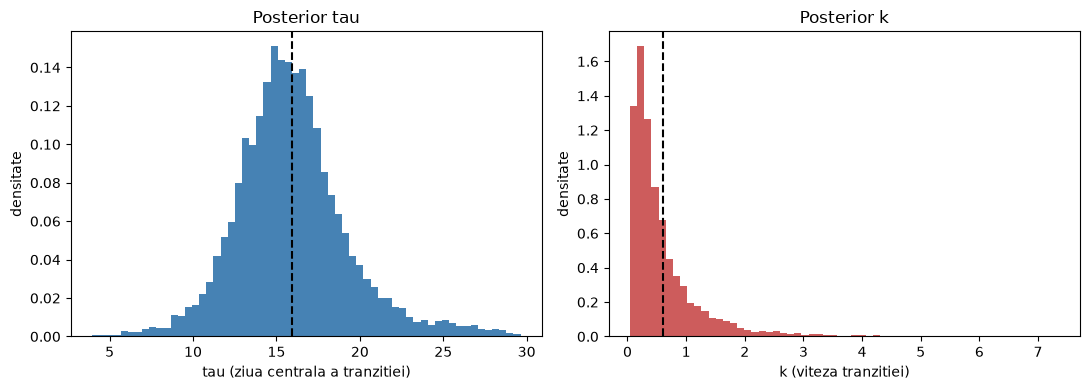

In [3]:
post = az.extract(idata)
tau_s = post["tau"].values
k_s = post["k"].values

hdi_tau = az.hdi(tau_s, prob=0.95)
hdi_k = az.hdi(k_s, prob=0.95)
print(f"tau: media = {tau_s.mean():.2f}, HDI 95% = [{hdi_tau[0]:.2f}, {hdi_tau[1]:.2f}]")
print(f"k:   media = {k_s.mean():.2f}, HDI 95% = [{hdi_k[0]:.2f}, {hdi_k[1]:.2f}]")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(tau_s, bins=60, density=True, color="steelblue")
ax[0].axvline(tau_s.mean(), color="black", ls="--")
ax[0].set_xlabel("tau (ziua centrala a tranzitiei)"); ax[0].set_ylabel("densitate")
ax[0].set_title("Posterior tau")
ax[1].hist(k_s, bins=60, density=True, color="indianred")
ax[1].axvline(k_s.mean(), color="black", ls="--")
ax[1].set_xlabel("k (viteza tranzitiei)"); ax[1].set_ylabel("densitate")
ax[1].set_title("Posterior k")
plt.tight_layout(); plt.show()

$\tau$ se concentrează spre mijlocul intervalului de observație (în jurul zilelor 14–17), acolo unde seria trece de la valori mici la valori mari. $k$ este mic și pozitiv (schimbare graduală).

## c) $P(\lambda_2 > \lambda_1 \mid Y)$ și evoluția estimată a lui $\lambda_t$

P(lam2 > lam1 | Y) = 1.0000


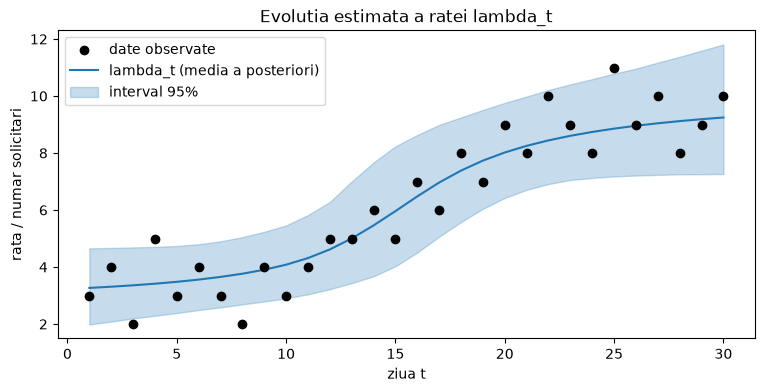

In [4]:
lam1_s = post["lam1"].values
lam2_s = post["lam2"].values
print(f"P(lam2 > lam1 | Y) = {(lam2_s > lam1_s).mean():.4f}")

# lam_t a posteriori: forma (30, n_esantioane)
lam_t_s = post["lam_t"].values
lam_mean = lam_t_s.mean(axis=1)
lam_lo = np.percentile(lam_t_s, 2.5, axis=1)
lam_hi = np.percentile(lam_t_s, 97.5, axis=1)

plt.figure(figsize=(9, 4))
plt.scatter(t, Y, color="black", zorder=3, label="date observate")
plt.plot(t, lam_mean, color="C0", label="lambda_t (media a posteriori)")
plt.fill_between(t, lam_lo, lam_hi, color="C0", alpha=0.25, label="interval 95%")
plt.xlabel("ziua t"); plt.ylabel("rata / numar solicitari")
plt.title("Evolutia estimata a ratei lambda_t")
plt.legend(); plt.show()

$P(\lambda_2 > \lambda_1 \mid Y) \approx 1$: datele susțin o creștere a ratei de solicitări. Curba $\lambda_t$ urmează panta datelor, de la un nivel inițial de $\approx 3$ la unul final de $\approx 10$ solicitări/zi.

## d) Distribuția predictivă a posteriori pentru cele 30 de zile

Generăm replici $\tilde Y_t$ din model folosind parametrii a posteriori și le comparăm cu datele observate.

Sampling: [Y]


Output()

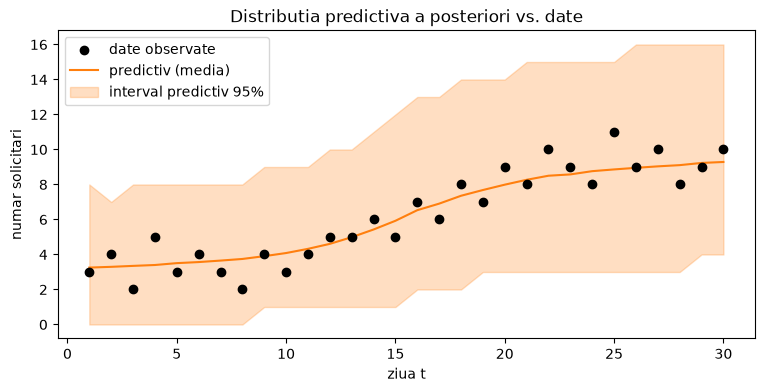

fractiunea de zile cu observatia in intervalul predictiv 95% = 1.00


In [5]:
with model:
    pp = pm.sample_posterior_predictive(idata, random_seed=42)

Yrep = pp.posterior_predictive["Y"].stack(s=("chain", "draw")).values  # (30, n_esantioane)
yrep_mean = Yrep.mean(axis=1)
yrep_lo = np.percentile(Yrep, 2.5, axis=1)
yrep_hi = np.percentile(Yrep, 97.5, axis=1)

plt.figure(figsize=(9, 4))
plt.scatter(t, Y, color="black", zorder=3, label="date observate")
plt.plot(t, yrep_mean, color="C1", label="predictiv (media)")
plt.fill_between(t, yrep_lo, yrep_hi, color="C1", alpha=0.25, label="interval predictiv 95%")
plt.xlabel("ziua t"); plt.ylabel("numar solicitari")
plt.title("Distributia predictiva a posteriori vs. date")
plt.legend(); plt.show()

acoperire = np.mean((Y >= yrep_lo) & (Y <= yrep_hi))
print(f"fractiunea de zile cu observatia in intervalul predictiv 95% = {acoperire:.2f}")

Media predictivă urmează aceeași traiectorie crescătoare ca $\lambda_t$, iar aproape toate observațiile cad în intervalul predictiv de 95% (banda include variabilitatea Poisson).